# Часть 2 из 8. Подготовка признаков и нормализация

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- удаление `price_per_sqm` и `id`, признаки из даты публикации: тренд, месяц, день недели;
- возраст дома вместо года постройки, доля жилой площади, кодирование категорий;
- корреляции Спирмена после кодирования и поиск сильно связанных пар признаков;
- разбиение на train / val / test, `QuantileTransformer` для числовых признаков, `log1p` для цены.

**Графики для отчёта:**
- рисунок 4 — медианная цена квартиры по месяцам публикации: [`figures/fig_04_median_price_by_month.png`](figures/fig_04_median_price_by_month.png)
- рисунок 5 — корреляции Спирмена после кодирования признаков: [`figures/fig_05_spearman_correlation.png`](figures/fig_05_spearman_correlation.png)

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре часть 1: `%run -i 01_eda.ipynb`.

← [Часть 1. Загрузка данных и разведочный анализ](01_eda.ipynb) · [Все части](README.md) · [Часть 3. Первое сравнение моделей: CatBoost, LightGBM, XGBoost](03_boosting_baselines.ipynb) →

## Работа с фичами

In [1]:
# Убрать цену за квадрат
df_sec_m = df_sec_m.drop(columns=['price_per_sqm', 'id'])

NameError: name 'df_sec_m' is not defined

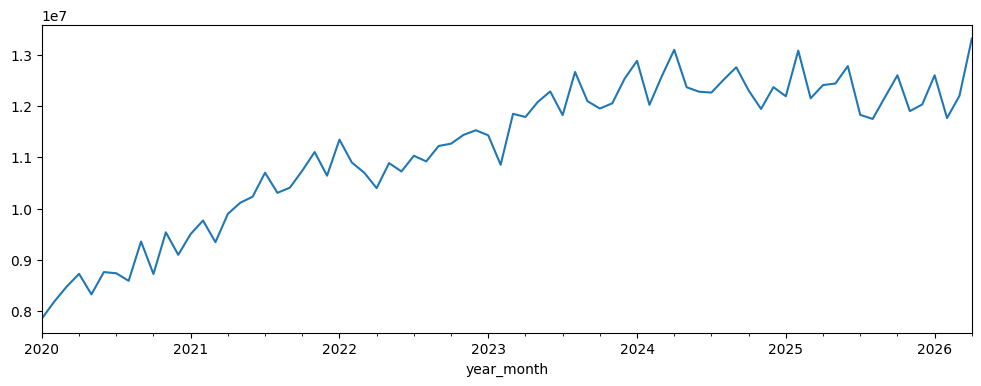

           date_ord  price_rub
date_ord   1.000000   0.190374
price_rub  0.190374   1.000000


In [ ]:
df_sec_m['date_posted'] = pd.to_datetime(df_sec_m['date_posted'])
df_sec_m['year_month'] = df_sec_m['date_posted'].dt.to_period('M')

# Средняя цена по месяцам
df_sec_m.groupby('year_month')['price_rub'].median().plot(figsize=(12, 4))
plt.show()

# Корреляция даты и цены (Спирмен)
df_sec_m['date_ord'] = df_sec_m['date_posted'].map(pd.Timestamp.toordinal)
print(df_sec_m[['date_ord', 'price_rub']].corr(method='spearman'))

In [ ]:
# ДАТА

# 1. Приводим к datetime
df_sec_m['date_posted'] = pd.to_datetime(df_sec_m['date_posted'], errors='coerce')

# 2. Линейный тренд рынка: месяцы от начала данных
date_min = df_sec_m['date_posted'].min()
df_sec_m['months_since_start'] = (
    (df_sec_m['date_posted'].dt.year  - date_min.year) * 12
    + (df_sec_m['date_posted'].dt.month - date_min.month)
).astype('float32')

# 3. Циклические признаки: месяц (сезонность)
df_sec_m['month_sin'] = np.sin(2 * np.pi * df_sec_m['date_posted'].dt.month / 12).astype('float32')
df_sec_m['month_cos'] = np.cos(2 * np.pi * df_sec_m['date_posted'].dt.month / 12).astype('float32')

# 4. Циклические признаки: день недели (активность рынка)
df_sec_m['dow_sin'] = np.sin(2 * np.pi * df_sec_m['date_posted'].dt.dayofweek / 7).astype('float32')
df_sec_m['dow_cos'] = np.cos(2 * np.pi * df_sec_m['date_posted'].dt.dayofweek / 7).astype('float32')

# 5. Дополнительно: квартал (грубая сезонность)
df_sec_m['quarter_sin'] = np.sin(2 * np.pi * df_sec_m['date_posted'].dt.quarter / 4).astype('float32')
df_sec_m['quarter_cos'] = np.cos(2 * np.pi * df_sec_m['date_posted'].dt.quarter / 4).astype('float32')

# 6. Удаляем исходную дату — она больше не нужна
df_sec_m = df_sec_m.drop(columns=['date_posted'])

# Проверка
print("Новые признаки:")
print(df_sec_m[['months_since_start', 'month_sin', 'month_cos',
                'dow_sin', 'dow_cos', 'quarter_sin', 'quarter_cos']].describe())

Новые признаки:
       months_since_start     month_sin     month_cos       dow_sin  \
count        50000.000000  5.000000e+04  5.000000e+04  50000.000000   
mean            37.458858  3.738302e-02  1.214971e-02     -0.002712   
std             21.868561  7.119077e-01  7.011863e-01      0.707106   
min              0.000000 -1.000000e+00 -1.000000e+00     -0.974928   
25%             19.000000 -5.000000e-01 -5.000000e-01     -0.781832   
50%             38.000000  1.224647e-16  6.123234e-17      0.000000   
75%             56.000000  8.660254e-01  8.660254e-01      0.781832   
max             75.000000  1.000000e+00  1.000000e+00      0.974928   

            dow_cos   quarter_sin   quarter_cos  
count  50000.000000  5.000000e+04  5.000000e+04  
mean       0.000843  3.820000e-02 -8.120000e-03  
std        0.707116  7.150042e-01  6.980428e-01  
min       -0.900969 -1.000000e+00 -1.000000e+00  
25%       -0.900969 -2.449294e-16 -1.836970e-16  
50%       -0.222521  1.224647e-16  6.123234e

In [ ]:
# Возраст вместо года
df_sec_m['building_age'] = 2026 - df_sec_m['building_year']
df_sec_m = df_sec_m.drop(columns=['building_year'])

In [ ]:
df_sec_m = df_sec_m.drop(columns=['total_floors'])

In [ ]:
df_sec_m['living_share'] = df_sec_m['living_area'] / df_sec_m['total_area'].clip(lower=1)

In [ ]:
# Кодирование
# Явно приводим булев к float32
cat_cols = df_sec_m.select_dtypes(include=['object', 'category']).columns.tolist()

# 2.1. Разделяем по числу уникальных значений
nunique = df_sec_m[cat_cols].nunique(dropna=True)

binary_cat_cols = [c for c in cat_cols if nunique[c] == 2]
binary_cat_cols.append("has_balcony")
multi_cat_cols  = [c for c in cat_cols if nunique[c] > 2]

print(f"Бинарных категориальных: {len(binary_cat_cols)}")
print(f"Многозначных категориальных: {len(multi_cat_cols)}")

# 2.2. Бинарные → 0/1 (float32, пойдут в bin_cols)
for c in binary_cat_cols:
    vals = df_sec_m[c].dropna().unique()
    df_sec_m[c] = df_sec_m[c].map({vals[0]: 0, vals[1]: 1}).astype('float32')

# 2.3. Многозначные → целочисленные коды (для эмбеддингов)
# ВАЖНО: кодируем по всему df, чтобы коды совпадали в train/val
cat_cardinalities = {}
for c in multi_cat_cols:
    df_sec_m[c] = df_sec_m[c].astype('category')
    cat_cardinalities[c] = len(df_sec_m[c].cat.categories)
    df_sec_m[c] = df_sec_m[c].cat.codes.astype('int64')

print("Кардинальности:", cat_cardinalities)

Бинарных категориальных: 3
Многозначных категориальных: 6
Кардинальности: {'district': 129, 'okrug': 11, 'building_type': 6, 'renovation': 4, 'metro_station': 104, 'metro_line': 12}


In [ ]:
df_sec_m.describe()

,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,floor,building_type,...,date_ord,months_since_start,month_sin,month_cos,dow_sin,dow_cos,quarter_sin,quarter_cos,building_age,living_share
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.00000,50000.000000
mean,63.774640,4.651960,55.712683,37.543657,67.053158,41.883782,11.244650,2.134900,7.475420,2.312560,...,738579.614840,37.458858,3.738302e-02,1.214971e-02,-0.002712,0.000843,3.820000e-02,-8.120000e-03,37.77992,0.624711
std,37.359904,2.819764,0.143998,0.180338,17.309579,11.209233,2.855538,1.023153,5.530469,1.550443,...,665.601676,21.868561,7.119077e-01,7.011863e-01,0.707106,0.707116,7.150042e-01,6.980428e-01,23.57096,0.043293
min,0.000000,0.000000,55.234080,36.699230,20.900000,12.600000,6.000000,1.000000,1.000000,0.000000,...,737425.000000,0.000000,-1.000000e+00,-1.000000e+00,-0.974928,-0.900969,-1.000000e+00,-1.000000e+00,2.00000,0.548926
25%,31.000000,2.000000,55.635415,37.467110,54.400000,33.700000,9.200000,1.000000,3.000000,1.000000,...,738005.000000,19.000000,-5.000000e-01,-5.000000e-01,-0.781832,-0.900969,-2.449294e-16,-1.836970e-16,17.00000,0.586986
50%,64.000000,5.000000,55.740110,37.565840,65.100000,40.600000,11.100000,2.000000,6.000000,2.000000,...,738582.000000,38.000000,1.224647e-16,6.123234e-17,0.000000,-0.222521,1.224647e-16,6.123234e-17,37.00000,0.624756
75%,96.000000,7.000000,55.817490,37.652020,77.500000,48.500000,13.100000,3.000000,10.000000,4.000000,...,739154.000000,56.000000,8.660254e-01,8.660254e-01,0.781832,0.623490,1.000000e+00,6.123234e-17,58.00000,0.662100
max,128.000000,10.000000,56.020470,37.919860,134.300000,89.200000,24.800000,5.000000,25.000000,5.000000,...,739735.000000,75.000000,1.000000e+00,1.000000e+00,0.974928,1.000000,1.000000e+00,1.000000e+00,91.00000,0.701128


In [ ]:
summary = pd.DataFrame({
    'dtype': df_sec_m.dtypes,
    'non_null': df_sec_m.notna().sum(),
    'null': df_sec_m.isna().sum(),
    'null_%': (df_sec_m.isna().mean() * 100).round(2),
    'unique': df_sec_m.nunique(),
    'example': [df_sec_m[c].dropna().iloc[0] if df_sec_m[c].notna().any() else None for c in df_sec_m.columns],
})
summary

,dtype,non_null,null,null_%,unique,example
district,int64,50000,0,0.0,129,7
okrug,int64,50000,0,0.0,11,2
lat,float64,50000,0,0.0,30403,55.79533
lon,float64,50000,0,0.0,33092,37.55519
total_area,float64,50000,0,0.0,1029,71.0
living_area,float64,50000,0,0.0,702,46.5
kitchen_area,float64,50000,0,0.0,170,6.1
rooms,int64,50000,0,0.0,5,2
floor,int64,50000,0,0.0,25,19
building_type,int64,50000,0,0.0,6,1


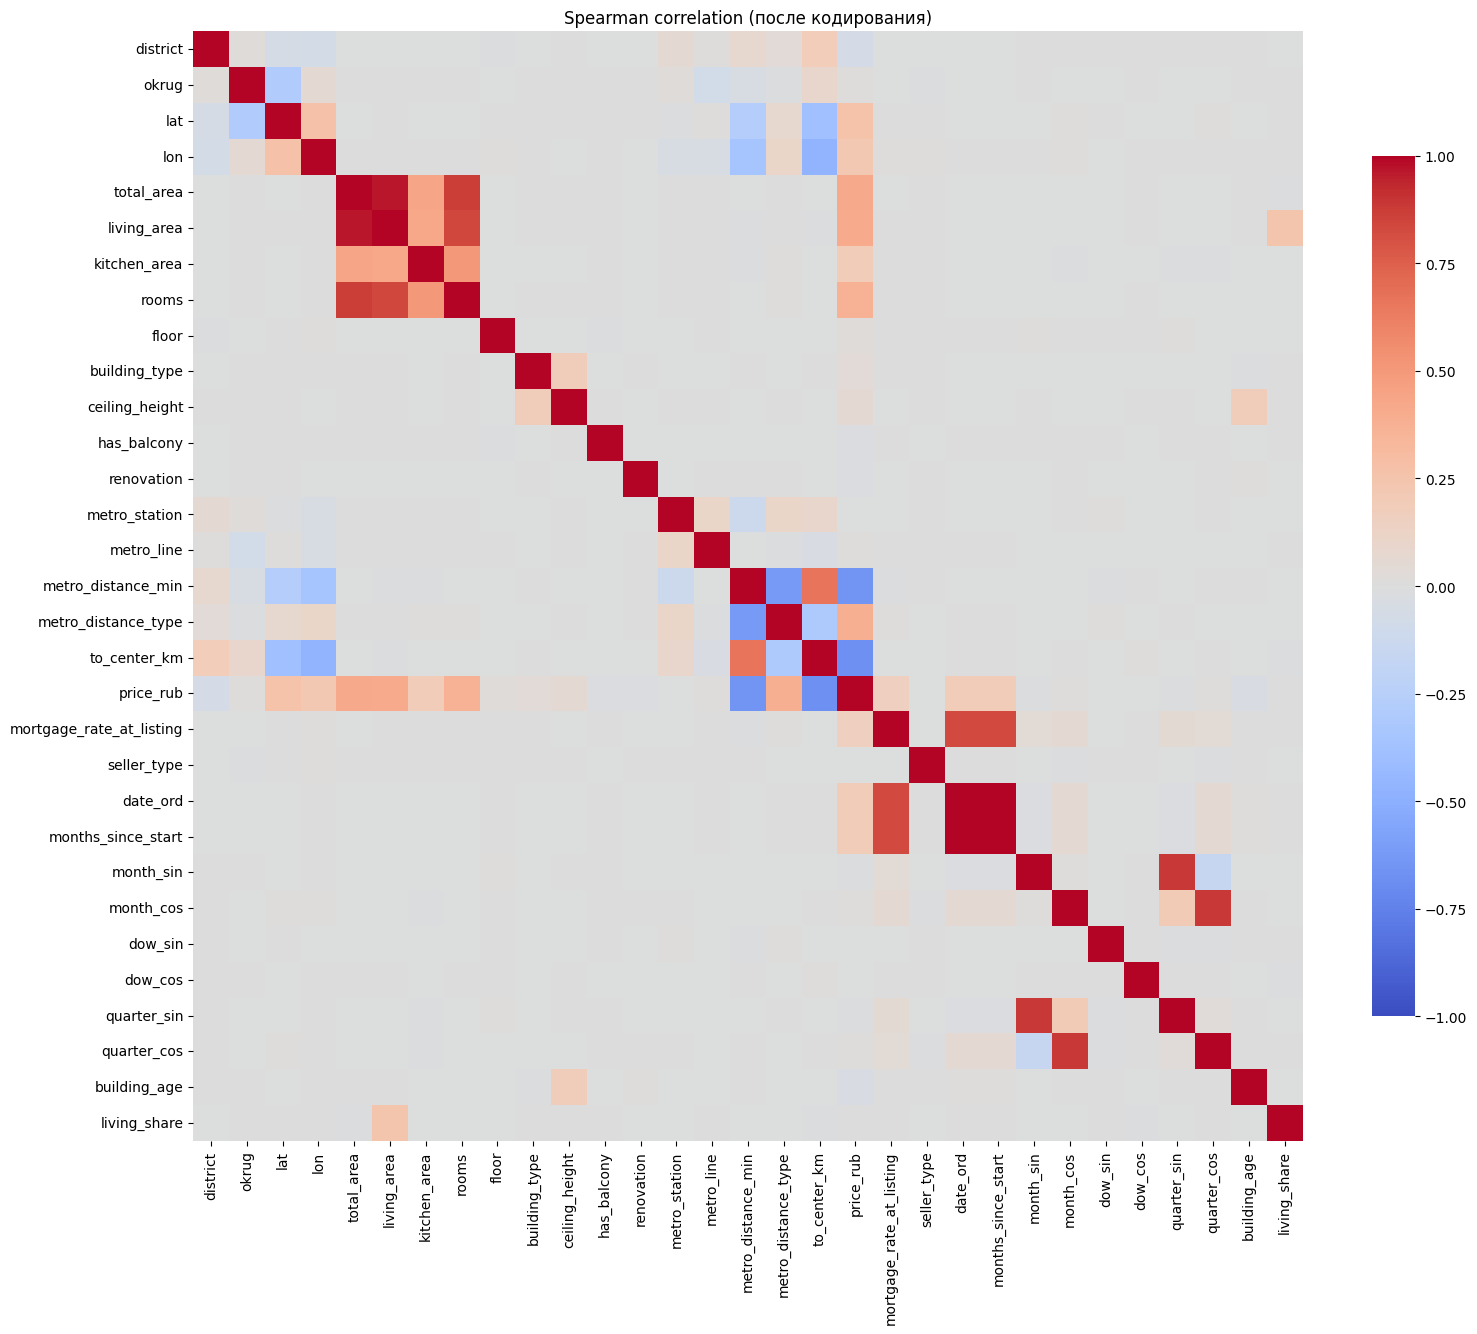

In [ ]:
corr = df_sec_m.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(16, 14))
sns.heatmap(
    corr, cmap='coolwarm', center=0,
    vmin=-1, vmax=1, square=True,
    cbar_kws={'shrink': 0.7}
)
plt.title('Spearman correlation (после кодирования)')
plt.tight_layout()
plt.show()

In [ ]:
target_corr = (
    df_sec_m.corr(method='spearman', numeric_only=True)['price_rub']
    .drop('price_rub')
    .sort_values(key=abs, ascending=False)
)

print(target_corr.head(30))

to_center_km               -0.678292
metro_distance_min         -0.652246
total_area                  0.420567
living_area                 0.409018
metro_distance_type         0.387308
rooms                       0.367675
lat                         0.263167
lon                         0.224219
kitchen_area                0.192598
months_since_start          0.190421
date_ord                    0.190374
mortgage_rate_at_listing    0.164043
district                   -0.065484
ceiling_height              0.055678
building_type               0.038378
building_age               -0.032497
renovation                 -0.022489
has_balcony                -0.018111
floor                       0.016536
month_sin                  -0.014896
okrug                       0.013893
quarter_sin                -0.013652
metro_line                  0.012619
month_cos                   0.008507
quarter_cos                 0.008026
metro_station              -0.005742
living_share                0.005585
d

In [ ]:
threshold = 0.85

corr_abs = corr.abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))

pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'col1', 'level_1': 'col2', 0: 'corr'})
    .sort_values('corr', ascending=False)
)
pairs = pairs[pairs['corr'] >= threshold]

print(pairs.head(40))

           col1                col2      corr
420    date_ord  months_since_start  0.999913
114  total_area         living_area  0.962369
447   month_cos         quarter_cos  0.888271
440   month_sin         quarter_sin  0.887428
116  total_area               rooms  0.869926


In [ ]:
df_sec_m = df_sec_m.drop(columns=['date_ord'], errors='ignore')
df_sec_m = df_sec_m.drop(columns=['quarter_sin', 'quarter_cos', 'year_month'])

In [ ]:
summary = pd.DataFrame({
    'dtype': df_sec_m.dtypes,
    'non_null': df_sec_m.notna().sum(),
    'null': df_sec_m.isna().sum(),
    'null_%': (df_sec_m.isna().mean() * 100).round(2),
    'unique': df_sec_m.nunique(),
    'example': [df_sec_m[c].dropna().iloc[0] if df_sec_m[c].notna().any() else None for c in df_sec_m.columns],
})
summary

,dtype,non_null,null,null_%,unique,example
district,int64,50000,0,0.0,129,7.000000e+00
okrug,int64,50000,0,0.0,11,2.000000e+00
lat,float64,50000,0,0.0,30403,5.579533e+01
lon,float64,50000,0,0.0,33092,3.755519e+01
total_area,float64,50000,0,0.0,1029,7.100000e+01
living_area,float64,50000,0,0.0,702,4.650000e+01
kitchen_area,float64,50000,0,0.0,170,6.100000e+00
rooms,int64,50000,0,0.0,5,2.000000e+00
floor,int64,50000,0,0.0,25,1.900000e+01
building_type,int64,50000,0,0.0,6,1.000000e+00


## Нормализация

In [ ]:
from sklearn.preprocessing import QuantileTransformer
from sklearn.model_selection import train_test_split

In [ ]:
TARGET = 'price_rub'

# Категориальные (для эмбеддингов)
cat_cols = ['district', 'okrug', 'metro_station', 'metro_line',
            'building_type', 'renovation']

# Циклические — не нормализуем
cyclic_cols = ['month_sin', 'month_cos', 'dow_sin', 'dow_cos']

# Бинарные — не нормализуем
bin_cols = ['has_balcony', 'metro_distance_type', 'seller_type']

# Числовые — нормализуем
excluded = set(cat_cols + cyclic_cols + bin_cols + [TARGET])
num_cols = [c for c in df_sec_m.columns if c not in excluded]
print("Числовые:", num_cols)

Числовые: ['lat', 'lon', 'total_area', 'living_area', 'kitchen_area', 'rooms', 'floor', 'ceiling_height', 'metro_distance_min', 'to_center_km', 'mortgage_rate_at_listing', 'months_since_start', 'building_age', 'living_share']


In [ ]:
from sklearn.model_selection import train_test_split
idx_train_val, idx_test = train_test_split(
    df_sec_m.index, test_size=0.15, random_state=42
)
idx_tr, idx_val = train_test_split(
    idx_train_val, test_size=0.176, random_state=42  # 15/85
)
print(f"Train: {len(idx_tr)}, Val: {len(idx_val)}")

Train: 35020, Val: 7480


In [ ]:
qt = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=min(1000, len(idx_tr)),
    random_state=42
)
# числовые
X_num_tr  = qt.fit_transform(
    df_sec_m.loc[idx_tr, num_cols]
).astype('float32')

X_num_val = qt.transform(
    df_sec_m.loc[idx_val, num_cols]
).astype('float32')

X_num_test = qt.transform(df_sec_m.loc[idx_test, num_cols]).astype('float32')

print("X_num_tr:", X_num_tr.shape, "| X_num_val:", X_num_val.shape)

X_num_tr: (35020, 14) | X_num_val: (7480, 14)


In [ ]:
# бинарные
X_bin_tr  = df_sec_m.loc[idx_tr,  bin_cols].astype('float32').values
X_bin_val = df_sec_m.loc[idx_val, bin_cols].astype('float32').values
X_bin_test = df_sec_m.loc[idx_test, bin_cols].astype('float32').values
# циклические
X_cyc_tr  = df_sec_m.loc[idx_tr,  cyclic_cols].astype('float32').values
X_cyc_val = df_sec_m.loc[idx_val, cyclic_cols].astype('float32').values
X_cyc_test = df_sec_m.loc[idx_test, cyclic_cols].astype('float32').values
print("X_bin_tr:", X_bin_tr.shape, "| X_cyc_tr:", X_cyc_tr.shape)

X_bin_tr: (35020, 3) | X_cyc_tr: (35020, 4)


In [ ]:
# Категориальный
X_cat_tr  = df_sec_m.loc[idx_tr,  multi_cat_cols].values.astype('int64')
X_cat_val = df_sec_m.loc[idx_val, multi_cat_cols].values.astype('int64')
X_cat_test = df_sec_m.loc[idx_test, multi_cat_cols].values.astype('int64')

print("X_cat_tr:", X_cat_tr.shape, "| X_cat_val:", X_cat_val.shape)

X_cat_tr: (35020, 6) | X_cat_val: (7480, 6)


In [ ]:
# Целевая log1p
y_tr  = np.log1p(df_sec_m.loc[idx_tr,  TARGET].values).astype('float32')
y_val = np.log1p(df_sec_m.loc[idx_val, TARGET].values).astype('float32')
y_test = np.log1p(df_sec_m.loc[idx_test, TARGET].values).astype('float32')
print("y_tr:", y_tr.shape, "| min:", y_tr.min(), "| max:", y_tr.max())

y_tr: (35020,) | min: 13.834333 | max: 18.352798


In [ ]:
# Сборка
X_cont_tr  = np.hstack([X_num_tr,  X_bin_tr,  X_cyc_tr])
X_cont_val = np.hstack([X_num_val, X_bin_val, X_cyc_val])
X_cont_test = np.hstack([X_num_test, X_bin_test, X_cyc_test])

n_cont = X_cont_tr.shape[1]
n_cat  = len(multi_cat_cols)

print(f"X_cont: {X_cont_tr.shape} | X_cat: {X_cat_tr.shape}")
print(f"n_cont={n_cont}, n_cat={n_cat}")

X_cont: (35020, 21) | X_cat: (35020, 6)
n_cont=21, n_cat=6


---
← [Часть 1. Загрузка данных и разведочный анализ](01_eda.ipynb) · [Все части](README.md) · [Часть 3. Первое сравнение моделей: CatBoost, LightGBM, XGBoost](03_boosting_baselines.ipynb) →